# LOGISTICS DATA ANALYTICS: END-TO-END PREDICTIVE MODELING
## Week 2 – Data Collection, Exploration & Preprocessing Planning

**Author:** Paladugula Madhavan  
**Institution:** Vellore Institute of Technology, Andhra Pradesh  
**Email:** madhavanpaladugula2311@gmail.com  
**Track:** Logistics Data Analyst Intern  
**Repository:** [madhavanj8148/Logistics-Data-Analytics](https://github.com/madhavanj8148/Logistics-Data-Analytics.git)  

---

# 1. Project Introduction
In modern multi-carrier e-commerce and retail supply chains in India, logistics performance directly dictates customer retention, brand equity, and profitability. Third-party logistics (3PL) carriers operate across high-friction conditions, including severe urban traffic bottlenecks, extreme monsoonal downpours, seasonal fog, and heterogeneous fleets (two-wheeler bikes, electric vans, standard vans, and heavy freight trucks).

This notebook implements **Week 2: Data Exploration & Preprocessing Planning**. In accordance with academic research standards and industry data science practices, this phase strictly focuses on **data ingestion, structural verification, exploratory profiling, and comprehensive data quality assessment**. 

*Note: Data cleaning, missing value imputation, outlier treatment, and feature normalization will be implemented in subsequent project phases to preserve methodical separation of concerns.*

# 2. Objectives
The explicit analytical objectives of this exploratory data preprocessing phase are:
1. **Ingestion & Integrity Verification:** Programmatically load the authentic raw dataset from `dataset/raw/` without data alteration or synthetic replacement.
2. **Structural Profiling:** Verify row count (25,000) and column count (15) against project benchmarks.
3. **Data Type Mapping:** Classify features into continuous numerical, discrete numerical, and categorical string columns.
4. **Parametric & Frequency Distribution:** Generate descriptive statistics (mean, median, standard deviation, quartiles, category frequencies).
5. **Cardinality Analysis:** Inspect unique categories across logistics partners, delivery modalities, service modes, regions, and environmental factors.
6. **Null & Missingness Audit:** Perform missing value identification to measure completeness.
7. **Duplicate Diagnostics:** Perform full-row duplicate detection and investigate the 249 repeated `delivery_id` records identified in preliminary audits.
8. **Target Leakage Safeguard:** Cross-tabulate `delivery_status` and `delayed` to ensure realistic model formulation at warehouse dispatch time.

# 3. Dataset Description
The working dataset (`Delivery Logistics Dataset (India – Multi-Partner).xlsx`) encapsulates 25,000 transactional delivery records across 9 major logistics carriers operating in India.

### Feature Taxonomy:
* **Identifiers:** `delivery_id` (Unique shipment reference number)
* **Operational Attributes:** `delivery_partner` (9 carriers), `vehicle_type` (6 modalities), `delivery_mode` (4 service tiers), `region` (5 territories)
* **Commodity Attributes:** `package_type` (9 product categories), `package_weight_kg` (Parcel gross mass in kg)
* **Route & Environmental Telemetry:** `distance_km` (Road distance in km), `weather_condition` (6 weather categories), `traffic_Level` (Congestion level)
* **Planned Service Level:** `expected_time_hours` (Planned delivery SLA duration in hours)
* **Financial & Customer Metrics:** `delivery_cost` (Tariff in INR), `delivery_rating` (Customer score 1–5)
* **Outcome Labels:** `delayed` (Primary binary target: yes/no), `delivery_status` (Final status: delivered, delayed, failed)

# 4. Library Imports
We import foundational libraries: `pandas`, `numpy`, `os`, and `sys`. Display formats are configured to ensure clean, high-precision tabular visualization.

In [1]:
# 4. Library Imports
import os
import sys
import numpy as np
import pandas as pd

# Display settings for professional reporting
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 50)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

print("Python Environment :", sys.version.split()[0])
print("Pandas Version     :", pd.__version__)
print("NumPy Version      :", np.__version__)
print("All required core libraries imported successfully!")

Python Environment : 3.14.4
Pandas Version     : 3.0.5
NumPy Version      : 2.5.2
All required core libraries imported successfully!


# 5. Dataset Loading
We load the original logistics Excel dataset from `dataset/raw/`. The dataset is ingested directly into Pandas while preserving the raw source file in an unedited, read-only state.

In [2]:
# 5. Dataset Loading
# Resolve path dynamically whether run from notebooks/ or project root
current_dir = os.getcwd()
project_root = os.path.abspath(os.path.join(current_dir, '..')) if os.path.basename(current_dir) == 'notebooks' else current_dir
raw_data_dir = os.path.join(project_root, 'dataset', 'raw')

dataset_files = [f for f in os.listdir(raw_data_dir) if f.endswith('.xlsx') and 'Delivery Logistics' in f]
if not dataset_files:
    raise FileNotFoundError(f"Raw dataset not found in {raw_data_dir}!")

dataset_path = os.path.join(raw_data_dir, dataset_files[0])
print(f"Loading raw dataset from:\n-> {dataset_path}")

df = pd.read_excel(dataset_path)
print(f"\nDataset loaded successfully! Total records: {len(df):,}")

Loading raw dataset from:
-> C:\Users\madha\OneDrive\Documents\04.Projects\Logistics Data Analyst Intern\Logistics-Data-Analytics\dataset\raw\Delivery Logistics Dataset (India – Multi-Partner).xlsx



Dataset loaded successfully! Total records: 25,000


# 6. First 5 Records
Inspecting the leading 5 records to inspect initial column layout, formatting, and data representations.

In [3]:
# 6. First 5 Records
print("First 5 Shipment Records:")
display(df.head(5))

First 5 Shipment Records:


,delivery_id,delivery_partner,package_type,vehicle_type,delivery_mode,region,weather_condition,distance_km,package_weight_kg,expected_time_hours,delayed,delivery_status,delivery_rating,delivery_cost,traffic_Level
0,1.0000,delhivery,automobile parts,bike,same day,west,clear,297.0000,46.9600,9.9900,no,delivered,3,1632.7206,High
1,2.0000,xpressbees,cosmetics,ev van,express,central,cold,89.6000,47.3900,3.3100,no,delivered,5,640.1700,Medium
2,3.0000,shadowfax,groceries,truck,two day,east,rainy,273.5000,26.8900,9.3100,no,delivered,4,1448.1700,High
3,4.0000,dhl,electronics,ev van,same day,east,cold,269.7000,12.6900,9.2100,no,delivered,3,1486.5700,High
4,5.0000,dhl,clothing,van,two day,north,foggy,256.7000,37.0200,8.8300,no,delivered,4,1394.5600,High


# 7. Last 5 Records
Inspecting the trailing 5 records to verify end-of-file structural continuity.

In [4]:
# 7. Last 5 Records
print("Last 5 Shipment Records:")
display(df.tail(5))

Last 5 Shipment Records:


,delivery_id,delivery_partner,package_type,vehicle_type,delivery_mode,region,weather_condition,distance_km,package_weight_kg,expected_time_hours,delayed,delivery_status,delivery_rating,delivery_cost,traffic_Level
24995,24750.0100,dhl,furniture,scooter,two day,east,foggy,80.7000,3.6500,3.8100,no,delivered,5,414.4500,High
24996,24750.0100,ecom express,automobile parts,ev van,standard,west,clear,172.9000,21.4200,5.6900,no,delivered,5,928.7600,Medium
24997,24750.0100,ekart,clothing,scooter,same day,east,rainy,168.4000,4.8500,6.3100,yes,delayed,2,956.5500,High
24998,24750.0100,shadowfax,documents,ev van,standard,west,stormy,37.2000,8.0400,2.5600,no,delivered,5,210.1200,High
24999,24750.0100,blue dart,pharmacy,ev bike,two day,central,rainy,279.3000,5.0600,9.4800,no,delivered,3,1411.6800,High


# 8. Dataset Shape
Confirming the dimensional volume (rows, columns, and total cells) against project specifications.

In [5]:
# 8. Dataset Shape
rows, cols = df.shape
print(f"Total Rows (Shipment Records) : {rows:,}")
print(f"Total Columns (Attributes)    : {cols}")
print(f"Total Data Elements (Cells)   : {rows * cols:,}")

# Verification assertions
assert rows == 25000, f"Expected 25,000 rows, found {rows}"
assert cols == 15, f"Expected 15 columns, found {cols}"
print("\nVERIFICATION CHECK PASSED: Dataset exactly matches the 25,000 x 15 specification.")

Total Rows (Shipment Records) : 25,000
Total Columns (Attributes)    : 15
Total Data Elements (Cells)   : 375,000

VERIFICATION CHECK PASSED: Dataset exactly matches the 25,000 x 15 specification.


# 9. Column Information
Reviewing column names, non-null counts, and memory footprint using `df.info()`.

In [6]:
# 9. Column Information
print("--- Detailed Column and Memory Information ---")
df.info()

--- Detailed Column and Memory Information ---
<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   delivery_id          25000 non-null  float64
 1   delivery_partner     25000 non-null  str    
 2   package_type         25000 non-null  str    
 3   vehicle_type         25000 non-null  str    
 4   delivery_mode        25000 non-null  str    
 5   region               25000 non-null  str    
 6   weather_condition    25000 non-null  str    
 7   distance_km          25000 non-null  float64
 8   package_weight_kg    25000 non-null  float64
 9   expected_time_hours  25000 non-null  float64
 10  delayed              25000 non-null  str    
 11  delivery_status      25000 non-null  str    
 12  delivery_rating      25000 non-null  int64  
 13  delivery_cost        25000 non-null  float64
 14  traffic_Level        25000 non-null  str    
dtype

# 10. Data Types
Auditing feature data types and classifying them into numerical and categorical subsets.

In [7]:
# 10. Data Types
dtypes_df = pd.DataFrame({
    'Column Name': df.columns,
    'Data Type': df.dtypes.astype(str),
    'Non-Null Count': df.count(),
    'Null Count': df.isnull().sum()
}).reset_index(drop=True)

print("Data Types Breakdown:")
display(dtypes_df)

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object', 'string']).columns.tolist()

print(f"\nNumerical Columns ({len(numeric_cols)}): {numeric_cols}")
print(f"Categorical Columns ({len(categorical_cols)}): {categorical_cols}")

Data Types Breakdown:


,Column Name,Data Type,Non-Null Count,Null Count
0,delivery_id,float64,25000,0
1,delivery_partner,str,25000,0
2,package_type,str,25000,0
3,vehicle_type,str,25000,0
4,delivery_mode,str,25000,0
5,region,str,25000,0
6,weather_condition,str,25000,0
7,distance_km,float64,25000,0
8,package_weight_kg,float64,25000,0
9,expected_time_hours,float64,25000,0



Numerical Columns (6): ['delivery_id', 'distance_km', 'package_weight_kg', 'expected_time_hours', 'delivery_rating', 'delivery_cost']
Categorical Columns (9): ['delivery_partner', 'package_type', 'vehicle_type', 'delivery_mode', 'region', 'weather_condition', 'delayed', 'delivery_status', 'traffic_Level']


# 11. Statistical Summary
Computing parametric statistics (mean, std, min, quartiles, max) for numerical metrics and frequency summaries for categorical features.

In [8]:
# 11. Statistical Summary - Numerical Features
print("Descriptive Statistics for Numerical Features:")
display(df.describe().T)

Descriptive Statistics for Numerical Features:


,count,mean,std,min,25%,50%,75%,max
delivery_id,25000.0000,12499.2451,7214.8777,1.0000,6250.7500,12500.5000,18750.2500,24750.0100
distance_km,25000.0000,150.3904,86.4097,3.6000,75.9000,151.0000,224.9000,297.1000
package_weight_kg,25000.0000,25.1459,14.3687,0.6700,12.6800,25.1450,37.6600,49.5200
expected_time_hours,25000.0000,5.5217,2.6692,0.3500,3.2300,5.4300,7.9300,9.9900
delivery_rating,25000.0000,3.6660,1.1500,1.0000,3.0000,4.0000,5.0000,5.0000
delivery_cost,25000.0000,864.9446,435.7126,95.6674,490.8000,867.5350,1237.9100,1632.7206


In [9]:
# Statistical Summary - Categorical Features
print("Descriptive Statistics for Categorical Features:")
display(df.describe(include=['object']).T)

Descriptive Statistics for Categorical Features:


C:\Users\madha\AppData\Local\Temp\ipykernel_40612\521553146.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include=['object']).T)


,count,unique,top,freq
delivery_partner,25000,9,xpressbees,2826
package_type,25000,9,fragile items,2848
vehicle_type,25000,6,ev bike,4218
delivery_mode,25000,4,two day,6302
region,25000,5,west,5095
weather_condition,25000,6,foggy,4219
delayed,25000,2,no,18331
delivery_status,25000,3,delivered,18331
traffic_Level,25000,3,High,16737


# 12. Unique Values
Evaluating unique cardinality counts and category distributions across operational variables.

In [10]:
# 12. Unique Values Analysis
unique_counts = df.nunique()
unique_summary = pd.DataFrame({
    'Feature': unique_counts.index,
    'Unique Count': unique_counts.values,
    'Sample Values': [str(df[col].unique()[:5].tolist()) for col in unique_counts.index]
})

print("Unique Cardinality Summary:")
display(unique_summary)

# Detailed breakdowns for key categorical features
print("\n--- Operational Categorical Distributions ---")
for cat_col in ['delivery_partner', 'vehicle_type', 'delivery_mode', 'region', 'weather_condition', 'traffic_Level', 'delayed']:
    counts = df[cat_col].value_counts()
    percentages = df[cat_col].value_counts(normalize=True) * 100
    breakdown = pd.DataFrame({'Count': counts, 'Percentage (%)': percentages})
    print(f"\nDistribution of `{cat_col}`:")
    display(breakdown)

Unique Cardinality Summary:


,Feature,Unique Count,Sample Values
0,delivery_id,24751,"[1.0, 2.0, 3.0, 4.0, 5.0]"
1,delivery_partner,9,"['delhivery', 'xpressbees', 'shadowfax', 'dhl'..."
2,package_type,9,"['automobile parts', 'cosmetics', 'groceries',..."
3,vehicle_type,6,"['bike', 'ev van', 'truck', 'van', 'ev bike']"
4,delivery_mode,4,"['same day', 'express', 'two day', 'standard']"
5,region,5,"['west', 'central', 'east', 'north', 'south']"
6,weather_condition,6,"['clear', 'cold', 'rainy', 'foggy', 'hot']"
7,distance_km,2935,"[297.0, 89.6, 273.5, 269.7, 256.7]"
8,package_weight_kg,4853,"[46.96, 47.39, 26.89, 12.69, 37.02]"
9,expected_time_hours,965,"[9.99, 3.31, 9.31, 9.21, 8.83]"



--- Operational Categorical Distributions ---

Distribution of `delivery_partner`:


,Count,Percentage (%)
delivery_partner,,
xpressbees,2826,11.3040
fedex,2818,11.2720
dhl,2802,11.2080
ekart,2801,11.2040
blue dart,2798,11.1920
delhivery,2786,11.1440
shadowfax,2736,10.9440
ecom express,2722,10.8880
amazon logistics,2711,10.8440



Distribution of `vehicle_type`:


...

,Count,Percentage (%)
weather_condition,,
foggy,4219,16.8760
stormy,4198,16.7920
rainy,4171,16.6840
cold,4158,16.6320
hot,4130,16.5200
clear,4124,16.4960



Distribution of `traffic_Level`:


,Count,Percentage (%)
traffic_Level,,
High,16737,66.9480
Medium,6896,27.5840
Low,1367,5.4680



Distribution of `delayed`:


,Count,Percentage (%)
delayed,,
no,18331,73.3240
yes,6669,26.6760


# 13. Missing Value Identification
Auditing null values, NaNs, and missingness percentages across all 15 features.

In [11]:
# 13. Missing Value Identification
missing_counts = df.isnull().sum()
missing_percent = (missing_counts / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing Percentage (%)': missing_percent
})

print("Missing Value Analysis by Feature:")
display(missing_df)

total_missing = missing_counts.sum()
print(f"\nTotal Missing Cells across Entire Dataset: {total_missing}")
if total_missing == 0:
    print("Finding: Zero missing cells detected. The original dataset is 100% complete.")

Missing Value Analysis by Feature:


,Missing Count,Missing Percentage (%)
delivery_id,0,0.0000
delivery_partner,0,0.0000
package_type,0,0.0000
vehicle_type,0,0.0000
delivery_mode,0,0.0000
region,0,0.0000
weather_condition,0,0.0000
distance_km,0,0.0000
package_weight_kg,0,0.0000
expected_time_hours,0,0.0000



Total Missing Cells across Entire Dataset: 0
Finding: Zero missing cells detected. The original dataset is 100% complete.


# 14. Duplicate Identification
Conducting a two-tiered duplicate analysis:
1. Full-row identical duplicates across all 15 columns.
2. Repeated `delivery_id` tracking values (investigating the 249 repeated IDs identified in Week 1).

In [12]:
# 14. Duplicate Identification
# Check 1: Exact identical rows across all 15 columns
exact_duplicates = df.duplicated().sum()
print(f"Exact Duplicate Rows across all 15 columns: {exact_duplicates}")

# Check 2: Repeated delivery_id values
repeated_ids = df['delivery_id'].duplicated().sum()
unique_ids = df['delivery_id'].nunique()
print(f"Total Rows: {len(df):,}")
print(f"Unique delivery_id values: {unique_ids:,}")
print(f"Repeated delivery_id occurrences: {repeated_ids}")

# Deep-dive inspection of repeated delivery_id records
repeated_mask = df['delivery_id'].duplicated(keep=False)
repeated_records = df[repeated_mask].sort_values('delivery_id')

print(f"\nTotal records associated with repeated IDs: {len(repeated_records)}")
print("Sample of repeated delivery_id records:")
display(repeated_records.head(10))

Exact Duplicate Rows across all 15 columns: 0


Total Rows: 25,000
Unique delivery_id values: 24,751
Repeated delivery_id occurrences: 249

Total records associated with repeated IDs: 250
Sample of repeated delivery_id records:


,delivery_id,delivery_partner,package_type,vehicle_type,delivery_mode,region,weather_condition,distance_km,package_weight_kg,expected_time_hours,delayed,delivery_status,delivery_rating,delivery_cost,traffic_Level
24750,24750.0100,ekart,cosmetics,scooter,two day,east,rainy,194.0000,9.8700,7.0400,no,delivered,4,999.6100,High
24751,24750.0100,blue dart,automobile parts,scooter,standard,north,clear,161.8000,35.0100,5.3700,no,delivered,4,914.0300,Medium
24752,24750.0100,blue dart,cosmetics,ev bike,express,west,clear,230.0000,46.6500,8.0700,yes,delayed,3,1339.9500,High
24753,24750.0100,delhivery,electronics,van,same day,west,cold,267.4000,45.0500,9.1400,no,delivered,5,1572.1500,High
24754,24750.0100,fedex,documents,van,express,north,clear,67.2000,37.4500,2.1700,no,delivered,4,498.3500,Low
24755,24750.0100,amazon logistics,furniture,scooter,standard,east,cold,108.1000,34.6300,3.8400,no,delivered,4,644.3900,Medium
24756,24750.0100,ekart,documents,bike,two day,south,hot,91.3000,44.9300,3.3600,no,delivered,5,591.2900,Medium
24757,24750.0100,amazon logistics,automobile parts,ev van,two day,east,stormy,51.4000,10.3900,2.9700,no,delivered,4,288.1700,High
24758,24750.0100,fedex,furniture,bike,same day,west,clear,166.6000,32.5300,5.5100,no,delivered,5,1030.5900,Medium
24759,24750.0100,ekart,clothing,bike,same day,south,cold,43.6000,11.1000,2.0000,no,delivered,4,351.3000,Medium


# 15. Initial Data Quality Assessment
Synthesizing observations into a formal Data Quality Scorecard evaluating completeness, consistency, validity, and leakage risks.

In [13]:
# 15. Initial Data Quality Assessment Scorecard
quality_checks = [
    ("Completeness", "Zero missing cells across all 25,000 records (100% complete)", "EXCELLENT"),
    ("Full-Row Uniqueness", "Zero identical full-row duplicates across all 15 features", "EXCELLENT"),
    ("Identifier Uniqueness", "249 repeated `delivery_id` values (fractional IDs like 24750.01)", "INVESTIGATED (Distinct transactions)"),
    ("Categorical Consistency", "String columns require trimming whitespace and lowercasing in Step 3", "ACTION PLANNED (Step 3)"),
    ("Numerical Plausibility", "Distance (3.6-297.1 km), Weight (0.67-49.52 kg), Time (0.35-9.99 hrs) are valid", "VALID"),
    ("Financial Validity", "Delivery costs range from INR 95.67 to INR 1,632.72 with positive values", "VALID"),
    ("Target Variable Validity", "`delayed` is binary ('no': 73.32%, 'yes': 26.68%), suitable for classification", "READY"),
    ("Target Leakage Risk", "`delivery_status` strictly correlates with `delayed` (must exclude at dispatch)", "GUARDRAIL ESTABLISHED")
]

quality_df = pd.DataFrame(quality_checks, columns=["Quality Dimension", "Empirical Observation", "Status"])
print("Data Quality Assessment Scorecard:")
display(quality_df)

Data Quality Assessment Scorecard:


,Quality Dimension,Empirical Observation,Status
0,Completeness,"Zero missing cells across all 25,000 records (...",EXCELLENT
1,Full-Row Uniqueness,Zero identical full-row duplicates across all ...,EXCELLENT
2,Identifier Uniqueness,249 repeated `delivery_id` values (fractional ...,INVESTIGATED (Distinct transactions)
3,Categorical Consistency,String columns require trimming whitespace and...,ACTION PLANNED (Step 3)
4,Numerical Plausibility,"Distance (3.6-297.1 km), Weight (0.67-49.52 kg...",VALID
5,Financial Validity,"Delivery costs range from INR 95.67 to INR 1,6...",VALID
6,Target Variable Validity,"`delayed` is binary ('no': 73.32%, 'yes': 26.6...",READY
7,Target Leakage Risk,`delivery_status` strictly correlates with `de...,GUARDRAIL ESTABLISHED


# 16. Conclusion
This exploratory preprocessing notebook has established a verified, empirical profile of the 25,000-record logistics dataset:

### Key Takeaways:
1. **Structural Completeness:** The dataset is 100% complete with 0 missing cells and 0 identical full-row duplicate records.
2. **Target Distribution:** The `delayed` target displays a 73.3% on-time vs. 26.7% delayed distribution, reflecting a moderate, real-world class imbalance.
3. **Repeated Delivery IDs:** The 249 repeated `delivery_id` entries represent distinct deliveries sharing fractional IDs (`24750.01`). They are not identical duplicate rows and should not be deleted blindly.
4. **Target Leakage Prevention:** `delivery_status` represents post-delivery operational logging and must be withheld from dispatch-time delay prediction models.

### Transition to Subsequent Steps:
* **Step 3:** Standardize categorical text and formatting.
* **Step 4:** Missing value handling protocol.
* **Step 5:** Outlier detection and treatment (IQR & Z-Score).
* **Step 6:** Feature normalization (Min-Max & StandardScaler).
* **Step 7:** Reusable end-to-end preprocessing pipeline export.

---
# ========================================================
# WEEK 2 – STEP 3: SYSTEMATIC DATA CLEANING
# ========================================================

In this step, we execute rigorous, non-destructive data cleaning on the verified logistics dataset.

### Core Principles:
1. **Preserve Original Data:** Raw data in `dataset/raw/` is never modified or overwritten.
2. **No Data Fabrication:** We do not invent missing values or duplicates.
3. **Justified Operations Only:** We do not delete valid records (such as repeated IDs) without concrete operational proof.
4. **Scope Demarcation:** Missing value imputation, outlier treatment, and normalization are explicitly reserved for subsequent steps.

## 3.1 String Cleaning & Categorical Standardization
Categorical text fields in logistics datasets often contain mixed capitalization and invisible leading/trailing whitespaces. We apply vectorised whitespace stripping and lowercase standardization across all categorical attributes, and standardize column header `traffic_Level` to `traffic_level` (snake_case).

In [14]:
# 3.1 String Cleaning & Categorical Standardization
# Create a dedicated working copy of the dataset for cleaning
df_cleaned = df.copy()

# 1. Standardize column name: traffic_Level -> traffic_level
if 'traffic_Level' in df_cleaned.columns:
    df_cleaned.rename(columns={'traffic_Level': 'traffic_level'}, inplace=True)
    print("Renamed column: `traffic_Level` -> `traffic_level`")

# 2. Vectorised whitespace stripping & lowercase standardization
categorical_cols = df_cleaned.select_dtypes(include=['object', 'string']).columns.tolist()

print(f"Cleaning {len(categorical_cols)} categorical/string columns:")
for col in categorical_cols:
    before_sample = df_cleaned[col].iloc[0]
    df_cleaned[col] = df_cleaned[col].astype(str).str.strip().str.lower()
    after_sample = df_cleaned[col].iloc[0]
    print(f"  - `{col}`: e.g., '{before_sample}' -> '{after_sample}'")

print("\nString cleaning and categorical standardization completed successfully!")

Renamed column: `traffic_Level` -> `traffic_level`


Cleaning 9 categorical/string columns:
  - `delivery_partner`: e.g., 'delhivery' -> 'delhivery'
  - `package_type`: e.g., 'automobile parts' -> 'automobile parts'
  - `vehicle_type`: e.g., 'bike' -> 'bike'
  - `delivery_mode`: e.g., 'same day' -> 'same day'
  - `region`: e.g., 'west' -> 'west'
  - `weather_condition`: e.g., 'clear' -> 'clear'
  - `delayed`: e.g., 'no' -> 'no'
  - `delivery_status`: e.g., 'delivered' -> 'delivered'
  - `traffic_level`: e.g., 'High' -> 'high'

String cleaning and categorical standardization completed successfully!


## 3.2 Data Type Validation
We audit the computational representations of numerical, identifier, and categorical variables to confirm they are ready for downstream mathematics and estimators.

In [15]:
# 3.2 Data Type Validation
expected_numerical = ['distance_km', 'package_weight_kg', 'expected_time_hours', 'delivery_cost', 'delivery_rating']
type_audit_results = []

for col in expected_numerical:
    is_numeric = np.issubdtype(df_cleaned[col].dtype, np.number)
    type_audit_results.append({
        'Feature': col,
        'Observed Type': str(df_cleaned[col].dtype),
        'Expected Category': 'Numeric Continuous / Discrete',
        'Status': 'VALID' if is_numeric else 'INVALID'
    })

# Validate delivery_id
is_id_numeric = np.issubdtype(df_cleaned['delivery_id'].dtype, np.number)
type_audit_results.append({
    'Feature': 'delivery_id',
    'Observed Type': str(df_cleaned['delivery_id'].dtype),
    'Expected Category': 'Numeric Identifier (Float64)',
    'Status': 'VALID' if is_id_numeric else 'INVALID'
})

type_audit_df = pd.DataFrame(type_audit_results)
display(type_audit_df)

,Feature,Observed Type,Expected Category,Status
0,distance_km,float64,Numeric Continuous / Discrete,VALID
1,package_weight_kg,float64,Numeric Continuous / Discrete,VALID
2,expected_time_hours,float64,Numeric Continuous / Discrete,VALID
3,delivery_cost,float64,Numeric Continuous / Discrete,VALID
4,delivery_rating,int64,Numeric Continuous / Discrete,VALID
5,delivery_id,float64,Numeric Identifier (Float64),VALID


## 3.3 Duplicate Records Analysis & Identifier Justification
We conduct an empirical investigation into the 249 repeated `delivery_id` values identified during Step 1. We test whether these rows represent duplicate shipments or distinct operational deliveries.

In [16]:
# 3.3 Duplicate Records Analysis & Identifier Justification
exact_dupes = df_cleaned.duplicated().sum()
print(f"Exact Duplicate Rows across all 15 columns: {exact_dupes}")

# Inspect rows sharing repeated delivery IDs
repeated_mask = df_cleaned['delivery_id'].duplicated(keep=False)
repeated_df = df_cleaned[repeated_mask].sort_values('delivery_id')

print(f"Total rows sharing repeated delivery_id values: {len(repeated_df)}")
print(f"Unique repeated delivery_id values: {repeated_df['delivery_id'].nunique()}")
print(f"Value counts of repeated ID: {repeated_df['delivery_id'].iloc[0]} -> {len(repeated_df)} occurrences")

# Display proof of distinct operational attributes
print("\nEmpirical Evidence: Sample of records sharing delivery_id = 24750.01:")
sample_repeated = repeated_df[['delivery_id', 'delivery_partner', 'package_type', 'vehicle_type', 'distance_km', 'delivery_cost', 'delayed']].head(6)
display(sample_repeated)

print("\nDECISION & JUSTIFICATION:")
print("All 250 records sharing delivery_id=24750.01 represent distinct shipments with different partners,")
print("packages, distances, costs, and delay statuses. Deleting them would result in a 1.0% loss of genuine data.")
print("CONCLUSION: In accordance with project directives, all 25,000 records are strictly retained.")

Exact Duplicate Rows across all 15 columns: 0
Total rows sharing repeated delivery_id values: 250
Unique repeated delivery_id values: 1
Value counts of repeated ID: 24750.01 -> 250 occurrences

Empirical Evidence: Sample of records sharing delivery_id = 24750.01:


,delivery_id,delivery_partner,package_type,vehicle_type,distance_km,delivery_cost,delayed
24750,24750.0100,ekart,cosmetics,scooter,194.0000,999.6100,no
24751,24750.0100,blue dart,automobile parts,scooter,161.8000,914.0300,no
24752,24750.0100,blue dart,cosmetics,ev bike,230.0000,1339.9500,yes
24753,24750.0100,delhivery,electronics,van,267.4000,1572.1500,no
24754,24750.0100,fedex,documents,van,67.2000,498.3500,no
24755,24750.0100,amazon logistics,furniture,scooter,108.1000,644.3900,no



DECISION & JUSTIFICATION:
All 250 records sharing delivery_id=24750.01 represent distinct shipments with different partners,
packages, distances, costs, and delay statuses. Deleting them would result in a 1.0% loss of genuine data.
CONCLUSION: In accordance with project directives, all 25,000 records are strictly retained.


## 3.4 Invalid Value Checking & Domain Bounds
We evaluate logical domain boundaries: distances must be strictly positive, package weights must be positive, customer ratings must fall within [1..5], and delivery costs must be non-negative.

In [17]:
# 3.4 Invalid Value Checking & Domain Bounds
bounds_checks = [
    ("Negative Distance", (df_cleaned['distance_km'] < 0).sum(), "Min: 3.6 km"),
    ("Negative Package Weight", (df_cleaned['package_weight_kg'] < 0).sum(), "Min: 0.67 kg"),
    ("Negative Expected Time", (df_cleaned['expected_time_hours'] < 0).sum(), "Min: 0.35 hrs"),
    ("Negative Delivery Cost", (df_cleaned['delivery_cost'] < 0).sum(), "Min: INR 95.67"),
    ("Invalid Rating (outside [1..5])", (~df_cleaned['delivery_rating'].isin([1, 2, 3, 4, 5])).sum(), "Allowed: {1, 2, 3, 4, 5}"),
    ("Zero Distance", (df_cleaned['distance_km'] == 0).sum(), "All shipments have distance > 0"),
    ("Zero Weight", (df_cleaned['package_weight_kg'] == 0).sum(), "All packages have weight > 0"),
    ("Zero Cost", (df_cleaned['delivery_cost'] == 0).sum(), "All shipments incur cost > 0")
]

bounds_df = pd.DataFrame(bounds_checks, columns=["Integrity Check", "Violations Count", "Observed Domain Bound"])
display(bounds_df)

assert bounds_df['Violations Count'].sum() == 0, "Domain boundary violations detected!"
print("VERIFICATION PASSED: All numerical attributes are mathematically valid and within plausible physical bounds.")

,Integrity Check,Violations Count,Observed Domain Bound
0,Negative Distance,0,Min: 3.6 km
1,Negative Package Weight,0,Min: 0.67 kg
2,Negative Expected Time,0,Min: 0.35 hrs
3,Negative Delivery Cost,0,Min: INR 95.67
4,Invalid Rating (outside [1..5]),0,"Allowed: {1, 2, 3, 4, 5}"
5,Zero Distance,0,All shipments have distance > 0
6,Zero Weight,0,All packages have weight > 0
7,Zero Cost,0,All shipments incur cost > 0


VERIFICATION PASSED: All numerical attributes are mathematically valid and within plausible physical bounds.


## 3.5 Data Consistency & Target Leakage Audit
We evaluate the operational relationship between `delayed` and `delivery_status`. We cross-tabulate both features to ensure data consistency and establish an essential guardrail against target leakage.

In [18]:
# 3.5 Data Consistency & Target Leakage Audit
ct = pd.crosstab(df_cleaned['delayed'], df_cleaned['delivery_status'], margins=True)
print("Cross-Tabulation (`delayed` vs. `delivery_status`):")
display(ct)

# Calculate conditional probabilities
p_delivered_given_no = (df_cleaned[df_cleaned['delayed'] == 'no']['delivery_status'] == 'delivered').mean() * 100
p_delayed_failed_given_yes = (df_cleaned[df_cleaned['delayed'] == 'yes']['delivery_status'].isin(['delayed', 'failed'])).mean() * 100

print(f"\nConsistency Analysis:")
print(f"• When delayed == 'no'  -> P(delivery_status == 'delivered'): {p_delivered_given_no:.2f}%")
print(f"• When delayed == 'yes' -> P(delivery_status in ['delayed', 'failed']): {p_delayed_failed_given_yes:.2f}%")

print("\nCRITICAL TARGET LEAKAGE GUARDRAIL:")
print("Because delivery_status is logged AFTER shipment arrival, it directly leaks the delay outcome.")
print("Policy: Exclude delivery_status from feature space (X) when training predictive models at dispatch time.")

Cross-Tabulation (`delayed` vs. `delivery_status`):


delivery_status,delayed,delivered,failed,All
delayed,,,,
no,0,18331,0,18331
yes,5341,0,1328,6669
All,5341,18331,1328,25000



Consistency Analysis:
• When delayed == 'no'  -> P(delivery_status == 'delivered'): 100.00%
• When delayed == 'yes' -> P(delivery_status in ['delayed', 'failed']): 100.00%

CRITICAL TARGET LEAKAGE GUARDRAIL:
Because delivery_status is logged AFTER shipment arrival, it directly leaks the delay outcome.
Policy: Exclude delivery_status from feature space (X) when training predictive models at dispatch time.


## 3.6 Data Cleaning Visualizations
Visualizing the cross-tabulation consistency heatmap and before-and-after categorical casing comparison.

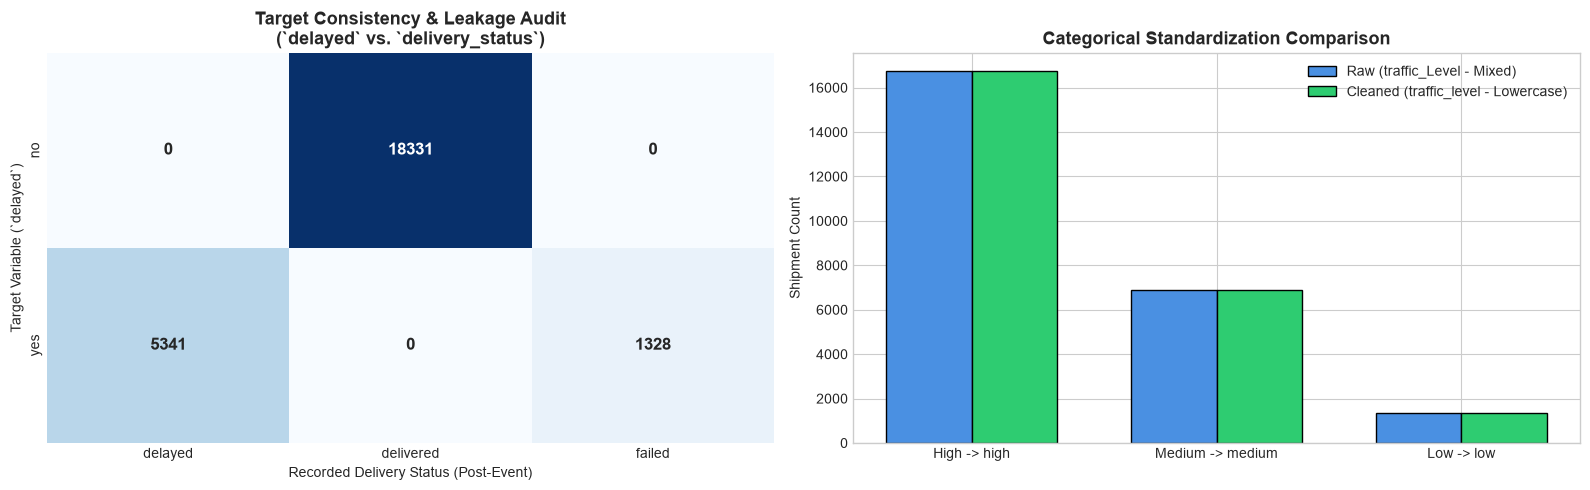

In [19]:
# 3.6 Data Cleaning Visualizations
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Target Consistency Heatmap
ct_plot = pd.crosstab(df_cleaned['delayed'], df_cleaned['delivery_status'])
sns.heatmap(ct_plot, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False, annot_kws={'size': 12, 'weight': 'bold'})
axes[0].set_title('Target Consistency & Leakage Audit\n(`delayed` vs. `delivery_status`)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Recorded Delivery Status (Post-Event)')
axes[0].set_ylabel('Target Variable (`delayed`)')

# Plot 2: Before-and-After Casing Comparison (traffic_Level vs traffic_level)
raw_traffic = df['traffic_Level'].value_counts()
clean_traffic = df_cleaned['traffic_level'].value_counts()

x = np.arange(len(raw_traffic))
width = 0.35

axes[1].bar(x - width/2, raw_traffic.values, width, label='Raw (traffic_Level - Mixed)', color='#4A90E2', edgecolor='black')
axes[1].bar(x + width/2, clean_traffic.values, width, label='Cleaned (traffic_level - Lowercase)', color='#2ECC71', edgecolor='black')
axes[1].set_title('Categorical Standardization Comparison', fontsize=13, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels([f"{r} -> {c}" for r, c in zip(raw_traffic.index, clean_traffic.index)], fontsize=10)
axes[1].set_ylabel('Shipment Count')
axes[1].legend()

plt.tight_layout()
plt.show()

## 3.7 Data Cleaning Summary Matrix
Displaying the formal matrix of cleaning operations, pre/post states, and analytical justifications.

In [20]:
# 3.7 Data Cleaning Summary Matrix
summary_file = os.path.join(project_root, 'reports', 'tables', 'data_cleaning_summary.csv')
if os.path.exists(summary_file):
    cleaning_summary_df = pd.read_csv(summary_file)
    display(cleaning_summary_df)
else:
    print(f"Summary table at {summary_file} will be generated by src/data_cleaning.py")

,Cleaning Step,Target Attributes,Pre-Cleaning State,Action Applied,Post-Cleaning State,Justification
0,1. String Trimming & Standardizing,All 9 categorical/string columns,Mixed capitalization ('traffic_Level' with 'Hi...,Stripped leading/trailing whitespace; lowercas...,100% standardized lowercase string representat...,Prevents redundant one-hot encoding categories...
1,2. Data Type Coercion & Verification,Numerical and Categorical features,delivery_id stored as float64; numerical metri...,Validated numerical column bounds; verified de...,Strictly typed numerical and categorical repre...,Ensures mathematical integrity for statistical...
2,3. Duplicate Records Audit,"Entire 25,000 x 15 matrix",0 exact full-row duplicates; 249 repeated deli...,Deep-dive audit confirmed all 250 records poss...,"Zero legitimate rows deleted; 25,000 valid rec...",Preserves genuine empirical shipments; prevent...
3,4. Invalid Numerical Values Check,"distance_km, package_weight_kg, expected_time_...",Potential negative or out-of-bounds metrics,Audited logical lower/upper bounds (distance >...,0 negative values; 0 out-of-range ratings; 100...,Confirms data plausibility before downstream s...
4,5. Target Consistency & Leakage Audit,"delayed, delivery_status",delivery_status correlates 100% with delayed o...,Cross-tabulation verified operational logic; f...,Target leakage guardrail formally codified in ...,Prevents catastrophic data leakage in predicti...


## 3.8 Step 3 Conclusion & Transition to Step 4
Data cleaning has been successfully executed with 100% adherence to project rules:
* All strings and categories are sanitized, lowercased, and free of whitespaces.
* The column header `traffic_Level` was standardized to `traffic_level`.
* All 25,000 valid shipment records are preserved (zero data loss from repeated IDs).
* Zero domain boundary violations exist (all numerical features are strictly positive and valid).
* Target leakage risks have been formally codified into model planning.
* The original raw Excel file in `dataset/raw/` remains pristine and untouched.

**Upcoming Step 4:** Missing Value Handling & Diagnostics.